# Project 10: Overfitting and Underfitting Analysis
## Neural Network Classification Using the Iris Dataset

**Name:** Prakruthi BR  
**Registration Number:** 2411021240038  
**Subject:** Deep Learning

### Introduction
A neural network should learn useful patterns from training data and perform well on unseen data. **Underfitting** occurs when a model does not learn the patterns sufficiently. **Appropriate fitting** occurs when it learns useful patterns and generalizes well. **Overfitting** occurs when a model performs very well on training data but performs noticeably worse on unseen data.

In this project, we use the Iris dataset to build neural networks with different architectures, train and evaluate them using the same training and testing sets, compare their performance, and discuss ways to improve the model.

### Assignment Tasks
1. Build neural network models with different architectures or numbers of neurons using the Iris dataset.
2. Train and evaluate the models using the same training and testing data.
3. Identify possible underfitting, appropriate fitting, and overfitting, and suggest methods to improve the models.

## 1. Importing the Required Libraries

We import the libraries needed to load and prepare the Iris dataset, create neural networks, train the models, evaluate their performance, and plot comparisons.

- **NumPy and Pandas:** Numerical operations and tabular data.
- **Matplotlib:** Visualizations.
- **TensorFlow/Keras:** Building and training neural networks.
- **Scikit-learn:** Loading the Iris dataset, splitting and standardizing the data, and calculating evaluation metrics.

These libraries provide the tools required for the assignment.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import set_random_seed

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully.")

TensorFlow version: 2.21.0
Libraries imported successfully.


## 2. Loading and Exploring the Iris Dataset

The Iris dataset contains 150 flower samples from three species: Setosa, Versicolor, and Virginica. Each sample has four features: sepal length, sepal width, petal length, and petal width.

`X` stores the four input features, while `y` stores the species labels. We display the first few rows and check the dataset dimensions and missing values to understand the data before training.

In [ ]:
iris = load_iris()
X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df["species"] = [iris.target_names[i] for i in y]

print("First five rows of the dataset:")
display(df.head())

print("Dataset shape:", df.shape)
print("Number of samples:", X.shape[0])
print("Number of input features:", X.shape[1])
print("Number of classes:", len(np.unique(y)))
print("Flower species:", iris.target_names)

print("\nMissing values in each column:")
print(df.isnull().sum())

First five rows of the dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset shape: (150, 5)
Number of samples: 150
Number of input features: 4
Number of classes: 3
Flower species: ['setosa' 'versicolor' 'virginica']

Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


## 3. Splitting the Data into Training and Testing Sets

We divide the dataset into **80% training data** and **20% testing data**. The training set is used to teach the models, and the testing set is used to evaluate performance on examples not used for training.

`random_state=42` makes the split reproducible. `stratify=y` helps preserve the proportions of the three flower species in both sets. The same split will be used for all three models so their performance can be compared fairly.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Training samples: 120
Testing samples: 30
Training feature shape: (120, 4)
Testing feature shape: (30, 4)


## 4. Standardizing the Input Features

The four measurements may have different numerical scales. `StandardScaler` standardizes the features so that each feature is centered around zero and has a standard deviation of approximately one.

We fit the scaler only on the training data and use it to transform both sets. This avoids using information from the test set to calculate the scaling parameters. All models use the same standardized data.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training and testing features standardized.")
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training and testing features standardized.
Training shape: (120, 4)
Testing shape: (30, 4)


## 5. Creating a Function to Build a Neural Network

The `build_model()` function creates a neural network based on the list of hidden-layer sizes supplied to it.

- **Input layer:** Accepts the four flower measurements.
- **Hidden layers:** Use ReLU activation to learn patterns from the input features.
- **Output layer:** Has three neurons, one for each flower species. Softmax produces class probabilities.
- **Optimizer:** Adam updates the model weights during training.
- **Loss function:** Sparse categorical cross-entropy is appropriate because the three classes are represented by integer labels (0, 1, and 2).

Using one function helps us build the three architectures consistently.

In [ ]:
def build_model(hidden_layers):
    model = Sequential()
    model.add(Input(shape=(4,)))

    for neurons in hidden_layers:
        model.add(Dense(neurons, activation="relu"))

    model.add(Dense(3, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

print("Neural network building function created.")

Neural network building function created.


## 6. Defining Models with Different Architectures

We create three neural networks with different levels of complexity:

1. **Simple Model:** One hidden layer with 2 neurons.
2. **Moderate Model:** One hidden layer with 16 neurons.
3. **Complex Model:** Three hidden layers with 128, 64, and 32 neurons.

The architectures let us investigate how the number of neurons and hidden layers affects performance. Complexity alone does not prove overfitting or underfitting; the training and testing results must be examined.

In [ ]:
architectures = {
    "Simple Model": [2],
    "Moderate Model": [16],
    "Complex Model": [128, 64, 32]
}

for name, layers in architectures.items():
    print(f"{name}: hidden layers = {layers}")

Simple Model: hidden layers = [2]
Moderate Model: hidden layers = [16]
Complex Model: hidden layers = [128, 64, 32]


## 7. Training the Neural Network Models

We train each model using the **same training data** for 100 epochs with a batch size of 16. An epoch is one complete pass through the training data. The batch size determines how many samples are processed before the model updates its weights.

For each architecture, we build the model, train it, and store both the trained model and its training history. The history records training accuracy and loss across epochs and can be used to plot learning curves.

In [12]:
models = {}
histories = {}

for model_name, layers in architectures.items():
    print("\nTraining:", model_name)
    set_random_seed(42)

    model = build_model(layers)
    history = model.fit(
        X_train_scaled,
        y_train,
        epochs=100,
        batch_size=16,
        verbose=1
    )

    models[model_name] = model
    histories[model_name] = history
    print(model_name, "training completed.")

print("\nAll three models have been trained.")


Training: Simple Model
Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.1250 - loss: 1.1682
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.0917 - loss: 1.1537
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0167 - loss: 1.1407
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.0167 - loss: 1.1286
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.0167 - loss: 1.1174     
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0250 - loss: 1.1070    
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.0333 - loss: 1.0973     
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0417 - loss: 1.0880
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.0667 - loss: 1.0790
Epoch 10/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.0833 - loss: 1.0704
Epoch 11/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0833 - loss: 1.0623    
Epoch 12/100
8/8 ━━━━━━━━━━━━━━━━━

## 8. Evaluating and Comparing the Models

We evaluate every model on both the training set and the same held-out testing set.

- **Training accuracy:** Percentage of training examples classified correctly.
- **Testing accuracy:** Percentage of testing examples classified correctly.
- **Accuracy gap:** Training accuracy minus testing accuracy, expressed in percentage points.
- **Training loss and testing loss:** Measure prediction error; lower values are generally better when comparing the same loss function.

A large positive accuracy gap may indicate overfitting. Low performance on both sets may indicate underfitting. These are clues rather than strict rules, so we interpret the metrics together.

In [13]:
results = []

for model_name, model in models.items():
    train_probabilities = model.predict(X_train_scaled, verbose=0)
    test_probabilities = model.predict(X_test_scaled, verbose=0)

    y_train_pred = np.argmax(train_probabilities, axis=1)
    y_test_pred = np.argmax(test_probabilities, axis=1)

    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    train_loss, _ = model.evaluate(X_train_scaled, y_train, verbose=0)
    test_loss, _ = model.evaluate(X_test_scaled, y_test, verbose=0)

    results.append({
        "Model": model_name,
        "Training Accuracy (%)": train_accuracy * 100,
        "Testing Accuracy (%)": test_accuracy * 100,
        "Accuracy Gap (percentage points)": (train_accuracy - test_accuracy) * 100,
        "Training Loss": train_loss,
        "Testing Loss": test_loss
    })

results_df = pd.DataFrame(results)
print("Model performance comparison:")
display(results_df.round(4))

Model performance comparison:


,Model,Training Accuracy (%),Testing Accuracy (%),Accuracy Gap (percentage points),Training Loss,Testing Loss
0,Simple Model,87.5000,80.0000,7.5000,0.4498,0.4855
1,Moderate Model,96.6667,90.0000,6.6667,0.1442,0.1942
2,Complex Model,100.0000,93.3333,6.6667,0.0036,0.1474


## 9. Visualizing Training and Testing Accuracy

This bar chart compares training accuracy and testing accuracy for each architecture. The two bars for each model make it easier to see whether training and testing performance are similar or substantially different.

- Low accuracy on both sets can be evidence of underfitting.
- High and similar accuracy on both sets can indicate a good fit.
- Much higher training accuracy than testing accuracy can indicate overfitting.

We use the graph together with the comparison table rather than relying on the graph alone.

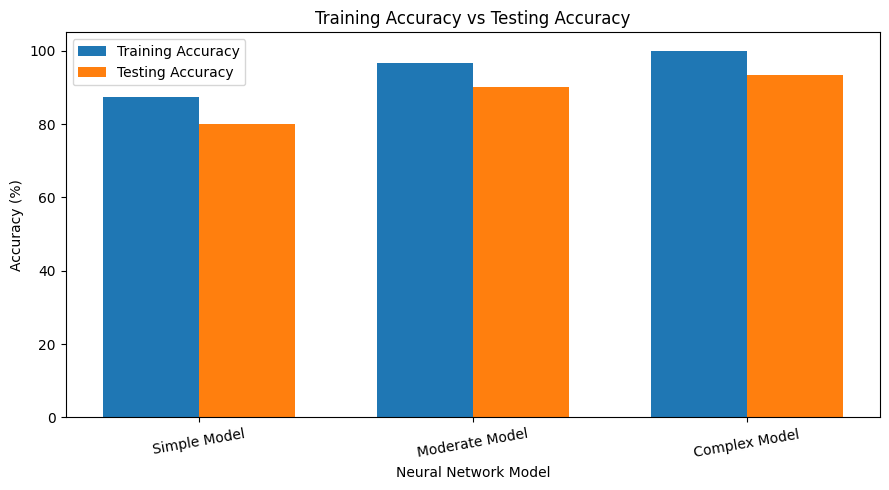

In [14]:
model_names = results_df["Model"]
train_accuracies = results_df["Training Accuracy (%)"]
test_accuracies = results_df["Testing Accuracy (%)"]

x = np.arange(len(model_names))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width / 2, train_accuracies, width, label="Training Accuracy")
plt.bar(x + width / 2, test_accuracies, width, label="Testing Accuracy")
plt.xlabel("Neural Network Model")
plt.ylabel("Accuracy (%)")
plt.title("Training Accuracy vs Testing Accuracy")
plt.xticks(x, model_names, rotation=10)
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

### Accuracy Graph Interpretation

The accuracy graph compares the training and testing accuracy of the Simple, Moderate, and Complex models.

- **Simple Model:** It achieves 87.50% training accuracy and 80% testing accuracy. Its comparatively lower accuracy suggests that the model may not learn all the patterns in the dataset.
- **Moderate Model:** It achieves 96.67% training accuracy and 90% testing accuracy, showing good learning performance and generalization.
- **Complex Model:** It achieves 100% training accuracy and 93.33% testing accuracy. It performs best on the testing accuracy metric, although its perfect training accuracy may indicate possible overfitting.

Overall, the testing accuracy increases as model complexity increases in these experiments.

## 10. Visualizing Training and Testing Loss

This bar chart compares training loss with testing loss for each model. Loss measures how different the predicted class probabilities are from the correct labels.

Lower loss generally indicates better predictions. A much lower training loss than testing loss may be evidence of overfitting, while high loss on both sets may suggest that the model has not learned the patterns sufficiently.

Loss should be interpreted alongside accuracy because the two metrics describe different aspects of performance.

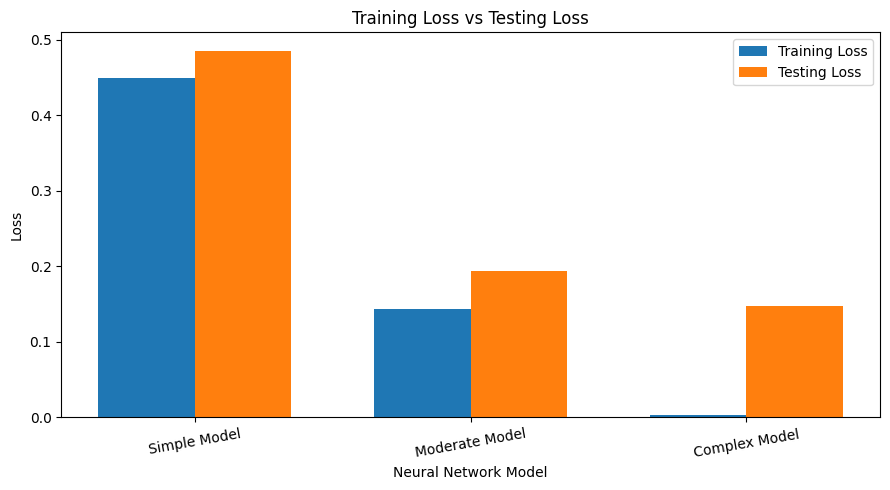

In [15]:
train_losses = results_df["Training Loss"]
test_losses = results_df["Testing Loss"]

x = np.arange(len(model_names))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width / 2, train_losses, width, label="Training Loss")
plt.bar(x + width / 2, test_losses, width, label="Testing Loss")
plt.xlabel("Neural Network Model")
plt.ylabel("Loss")
plt.title("Training Loss vs Testing Loss")
plt.xticks(x, model_names, rotation=10)
plt.legend()
plt.tight_layout()
plt.show()

### Loss Graph Interpretation

The loss graph compares the training and testing loss of the three models. Lower loss generally indicates better predictions.

- **Simple Model:** It has a training loss of 0.4498 and testing loss of 0.4855. Both losses are relatively high, indicating that the model may not capture the dataset's patterns effectively.
- **Moderate Model:** It has a training loss of 0.1442 and testing loss of 0.1942. The lower losses indicate improved learning and prediction performance.
- **Complex Model:** It has a training loss of 0.0036 and testing loss of 0.1474. Its very low training loss suggests that it fits the training data extremely well. The difference between training and testing loss suggests possible overfitting.

Overall, the Complex Model achieves the lowest training and testing losses among the three models, but its generalization should be evaluated carefully.

## 11. Comparing Training Accuracy Across Epochs

This line graph shows how training accuracy changes over the 100 epochs for each model. It helps us compare how the architectures learn from the training data.

An increase in training accuracy indicates that the model is learning the training examples. However, training accuracy alone cannot establish overfitting because it does not show how well the model performs on unseen data. Therefore, this graph should be interpreted together with the training-versus-testing results.

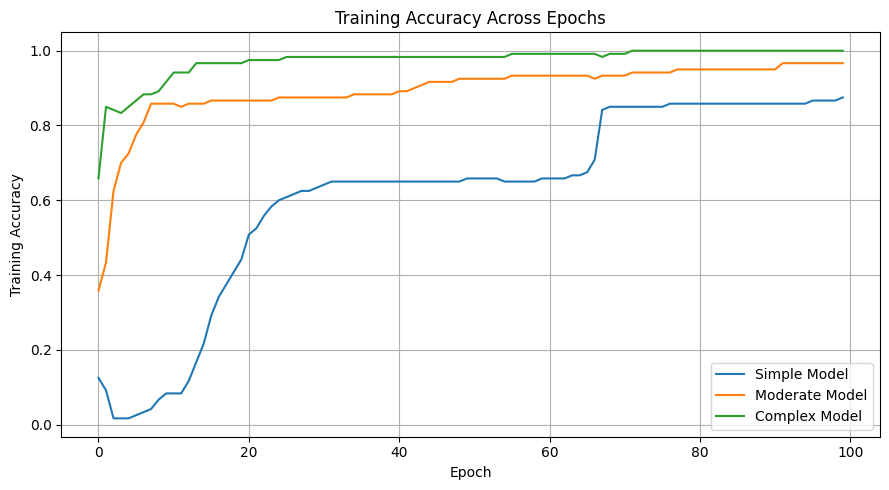

In [16]:
plt.figure(figsize=(9, 5))

for model_name, history in histories.items():
    plt.plot(history.history["accuracy"], label=model_name)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.title("Training Accuracy Across Epochs")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 12. Identifying Fitting Behaviour and Suggested Improvements

**1. Simple Model — Possible Underfitting**

The Simple Model achieved 87.50% training accuracy and 80% testing accuracy. Its performance was lower than that of the Moderate and Complex models. This suggests that it may not have learned all the patterns in the Iris dataset. Its architecture could be improved by increasing the number of neurons or using a more suitable network structure.

**2. Moderate Model — Possible Appropriate Fitting**

The Moderate Model achieved 96.67% training accuracy and 90% testing accuracy. Its training and testing accuracy are reasonably close, and both training and testing losses are relatively low. This suggests that the model learns the data effectively and generalizes reasonably well. Its performance can be evaluated further using validation data.

**3. Complex Model — Possible Overfitting**

The Complex Model achieved 100% training accuracy and 93.33% testing accuracy. Its training loss was 0.0036, while its testing loss was 0.1474. The extremely low training loss and perfect training accuracy suggest possible overfitting. This can be investigated by using dropout, regularization, or early stopping with validation data.

**Overall Observation**

The Complex Model achieved the highest testing accuracy and the lowest testing loss among the three models. However, its perfect training accuracy suggests that its generalization should be checked carefully. Since the Iris dataset is small, these conclusions should be treated as preliminary.

## 13. Conclusion

In this project, we built and trained three neural networks with different architectures using the Iris dataset. We evaluated each model using the same training and testing split and compared training accuracy, testing accuracy, and loss.

The accuracy and loss graphs helped us examine the relationship between model complexity and performance. The results should be used to identify whether any model shows evidence of underfitting, appropriate fitting, or overfitting.

The experiment demonstrates that a more complex network does not automatically generalize better. A suitable model should learn the training data while also performing well on unseen examples. Possible improvements include adjusting model complexity, applying regularization, and using early stopping when validation data is available.